# 02 · Controlled simulation study: can each generator recover a tail we know?

The E5 project asks for "controlled simulation studies, in which tail properties are known".
This notebook is a small version of one.

**Three true worlds.** All use the correlation matrix and margins fitted to the real Cumbria
*training* winters:

* **Gaussian world**: the chance that two cells are both extreme vanishes at the highest levels
  (asymptotic independence).
* **Student-t world** (4 degrees of freedom): joint extremes stay likely however high the level
  (asymptotic dependence), closer to how large storms behave.
* **Student-t world with varying tail shape**: as the Student-t world, but the true GPD shape ξ
  varies from west to east across the box (from the fitted value − 0.1 to + 0.1). The EVT margins
  assume one shared ξ, so here they are **misspecified**.

**Read the first two worlds as best cases.** Their true margins have exactly the form of the
fitted EVT margins (GPD above the 95th percentile, one shared ξ), and the Gaussian world *is* the
Gaussian copula + EVT generator. So in the Gaussian world the copula is correctly specified by
construction. The third world removes the first of these advantages.

**Each replicate** draws a synthetic training set (7,107 days) and validation set (2,370 days),
the sizes of the real ones, fits the four generators exactly as for the real data, and compares
their quantiles with the **true** quantiles. Levels go well beyond the synthetic training data:
one day in 1,000, one in 10,000, and one in 100,000 (the training set has about 7,000 days).

**Metrics:** log(model quantile / true quantile), averaged over cells or areas (0 = unbiased,
−0.1 ≈ 10% too low), and the mean *absolute* log ratio, in which errors of opposite sign in
different cells cannot cancel. Synthetic days are independent, unlike real days.

To rerun the study (about 1 hour per world on a 2-core CPU), set `RUN = True`.

In [1]:
# Setup: works locally (from the repository root or notebooks/) and on Google Colab
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("rainfall-extremes-pilot").exists():
    !git clone -q https://github.com/RidhimaGupta4/rainfall-extremes-pilot.git
    os.chdir("rainfall-extremes-pilot")
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data" / "cumbria_winter_rainfall_5km.nc"
RESULTS = Path(os.environ.get("RAINPILOT_RESULTS", ROOT / "results"))
FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True)
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

In [2]:
import json, subprocess
RUN = False
if RUN:
    for w in ["gaussian", "t", "t_varxi"]:
        subprocess.run([sys.executable, str(ROOT / "experiments/simulation_study.py"), "--reps", "3",
                        "--worlds", w], check=True)
res = json.loads((RESULTS / "simulation_study.json").read_text())
NAMES = ['Gaussian copula + empirical margins', 'Gaussian copula + EVT margins', 'VAE + empirical margins', 'VAE + EVT margins']
COL = {"Gaussian copula + empirical margins": "#9ecae1", "Gaussian copula + EVT margins": "#0072B2", "VAE + empirical margins": "#fdae6b", "VAE + EVT margins": "#D55E00"}
WNAME = {"gaussian": "Gaussian", "t": "Student-t", "t_varxi": "Student-t, varying xi"}
WORLDS = [w for w in WNAME if w in res["worlds"]]
PS = res["settings"]["ps"]; LBL = {str(p): f"1 in {round(1/(1-p)):,}" for p in PS}
for w in WORLDS:
    tx = np.array(res["worlds"][w]["truth_xi"])
    print(f"{WNAME[w]:22s} true xi {tx.min():.4f} to {tx.max():.4f} | fitted shared xi per replicate:",
          [round(r["fitted_xi"], 4) for r in res["worlds"][w]["reps"]])

Gaussian               true xi 0.0775 to 0.0775 | fitted shared xi per replicate: [0.1375, 0.0775, -0.0075]
Student-t              true xi 0.0775 to 0.0775 | fitted shared xi per replicate: [0.0725, 0.0525, -0.0025]
Student-t, varying xi  true xi -0.0225 to 0.1775 | fitted shared xi per replicate: [0.0825, -0.0075, 0.0825]


## Bias in tail quantiles, single cells and the whole box

Each entry is the mean over 3 replicates, with the range over replicates in brackets. With three
replicates this shows the spread between datasets; it is not a confidence interval.

In [3]:
import pandas as pd
rows = []
for w in WORLDS:
    wd = res["worlds"][w]
    for name in NAMES:
        for tile, tname in [("1", "single cell"), ("16", "80 km box")]:
            for p in PS:
                v = np.array([r["models"][name]["log_ratio"][tile][str(p)] for r in wd["reps"]])
                a = np.array([r["models"][name]["log_ratio_abs"][tile][str(p)] for r in wd["reps"]])
                rows.append({"world": WNAME[w], "model": name, "scale": tname, "level": LBL[str(p)],
                             "bias": f"{v.mean():+.2f} ({v.min():+.2f} to {v.max():+.2f})",
                             "mean |log ratio|": f"{a.mean():.2f}"})
tab = pd.DataFrame(rows)
tab.pivot_table(index=["world", "scale", "model"], columns="level", values="bias", aggfunc="first",
                sort=False)[[LBL[str(p)] for p in PS]]

level                                                                              1 in 1,000  \
world                 scale       model                                                         
Gaussian              single cell Gaussian copula + empirical margins  +0.00 (-0.09 to +0.10)   
                                  Gaussian copula + EVT margins        -0.02 (-0.10 to +0.07)   
                                  VAE + empirical margins              -0.08 (-0.19 to +0.11)   
                                  VAE + EVT margins                    -0.10 (-0.21 to +0.07)   
                      80 km box   Gaussian copula + empirical margins  -0.00 (-0.09 to +0.09)   
                                  Gaussian copula + EVT margins        -0.02 (-0.11 to +0.06)   
                                  VAE + empirical margins              -0.09 (-0.22 to +0.12)   
                                  VAE + EVT margins                    -0.11 (-0.23 to +0.09)   
Student-t             single cell Gaussian copula + empirical margins  -0.01 (-0.13 to +0.05)   
                                  Gaussian copula + EVT margins        -0.04 (-0.14 to +0.01)   
                                  VAE + empirical margins              -0.05 (-0.19 to +0.03)   
                                  VAE + EVT margins                    -0.09 (-0.21 to -0.02)   
                      80 km box   Gaussian copula + empirical margins  -0.06 (-0.16 to -0.01)   
                                  Gaussian copula + EVT margins        -0.08 (-0.17 to -0.03)   
                                  VAE + empirical margins              -0.09 (-0.25 to +0.01)   
                                  VAE + EVT margins                    -0.11 (-0.26 to -0.02)   
Student-t, varying xi single cell Gaussian copula + empirical margins  +0.00 (-0.08 to +0.05)   
                                  Gaussian copula + EVT margins        -0.02 (-0.09 to +0.05)   
                                  VAE + empirical margins              -0.10 (-0.17 to -0.02)   
                                  VAE + EVT margins                    -0.11 (-0.19 to -0.01)   
                      80 km box   Gaussian copula + empirical margins  -0.04 (-0.11 to +0.01)   
                                  Gaussian copula + EVT margins        -0.06 (-0.12 to +0.00)   
                                  VAE + empirical margins              -0.13 (-0.21 to -0.03)   
                                  VAE + EVT margins                    -0.14 (-0.23 to -0.03)   

level                                                                             1 in 10,000  \
world                 scale       model                                                         
Gaussian              single cell Gaussian copula + empirical margins  -0.03 (-0.21 to +0.10)   
                                  Gaussian copula + EVT margins        -0.02 (-0.20 to +0.15)   
                                  VAE + empirical margins              -0.16 (-0.35 to +0.10)   
                                  VAE + EVT margins                    -0.16 (-0.36 to +0.15)   
                      80 km box   Gaussian copula + empirical margins  -0.05 (-0.20 to +0.09)   
                                  Gaussian copula + EVT margins        -0.02 (-0.19 to +0.14)   
                                  VAE + empirical margins              -0.18 (-0.38 to +0.11)   
                                  VAE + EVT margins                    -0.17 (-0.39 to +0.17)   
Student-t             single cell Gaussian copula + empirical margins  -0.16 (-0.26 to -0.11)   
                                  Gaussian copula + EVT margins        -0.08 (-0.23 to +0.01)   
                                  VAE + empirical margins              -0.18 (-0.29 to -0.12)   
                                  VAE + EVT margins                    -0.14 (-0.29 to -0.03)   
                      80 km box   Gaussian copula + empirical margins  -0.20 (-0.30 to -0.14)   
                      

In [4]:
# Single cells: mean absolute log ratio (cell errors of opposite sign cannot cancel)
tab[tab.scale == "single cell"].pivot_table(index=["world", "model"], columns="level",
    values="mean |log ratio|", aggfunc="first", sort=False)[[LBL[str(p)] for p in PS]]

level                                                     1 in 1,000  \
world                 model                                            
Gaussian              Gaussian copula + empirical margins       0.08   
                      Gaussian copula + EVT margins             0.07   
                      VAE + empirical margins                   0.15   
                      VAE + EVT margins                         0.14   
Student-t             Gaussian copula + empirical margins       0.08   
                      Gaussian copula + EVT margins             0.06   
                      VAE + empirical margins                   0.10   
                      VAE + EVT margins                         0.09   
Student-t, varying xi Gaussian copula + empirical margins       0.06   
                      Gaussian copula + EVT margins             0.06   
                      VAE + empirical margins                   0.11   
                      VAE + EVT margins                         0.12   

level                                                     1 in 10,000  \
world                 model                                             
Gaussian              Gaussian copula + empirical margins        0.16   
                      Gaussian copula + EVT margins              0.13   
                      VAE + empirical margins                    0.23   
                      VAE + EVT margins                          0.26   
Student-t             Gaussian copula + empirical margins        0.17   
                      Gaussian copula + EVT margins              0.09   
                      VAE + empirical margins                    0.19   
                      VAE + EVT margins                          0.15   
Student-t, varying xi Gaussian copula + empirical margins        0.15   
                      Gaussian copula + EVT margins              0.14   
                      VAE + empirical margins                    0.16   
                      VAE + EVT margins                          0.18   

level                                                     1 in 100,000  
world                 model                                             
Gaussian              Gaussian copula + empirical margins         0.37  
                      Gaussian copula + EVT margins               0.19  
                      VAE + empirical margins                     0.37  
                      VAE + EVT margins                           0.36  
Student-t             Gaussian copula + empirical margins         0.50  
                      Gaussian copula + EVT margins               0.13  
                      VAE + empirical margins                     0.50  
                      VAE + EVT margins                           0.20  
Student-t, varying xi Gaussian copula + empirical margins         0.33  
                      Gaussian copula + EVT margins               0.22  
                      VAE + empirical margins                     0.33  
                      VAE + EVT margins                           0.25

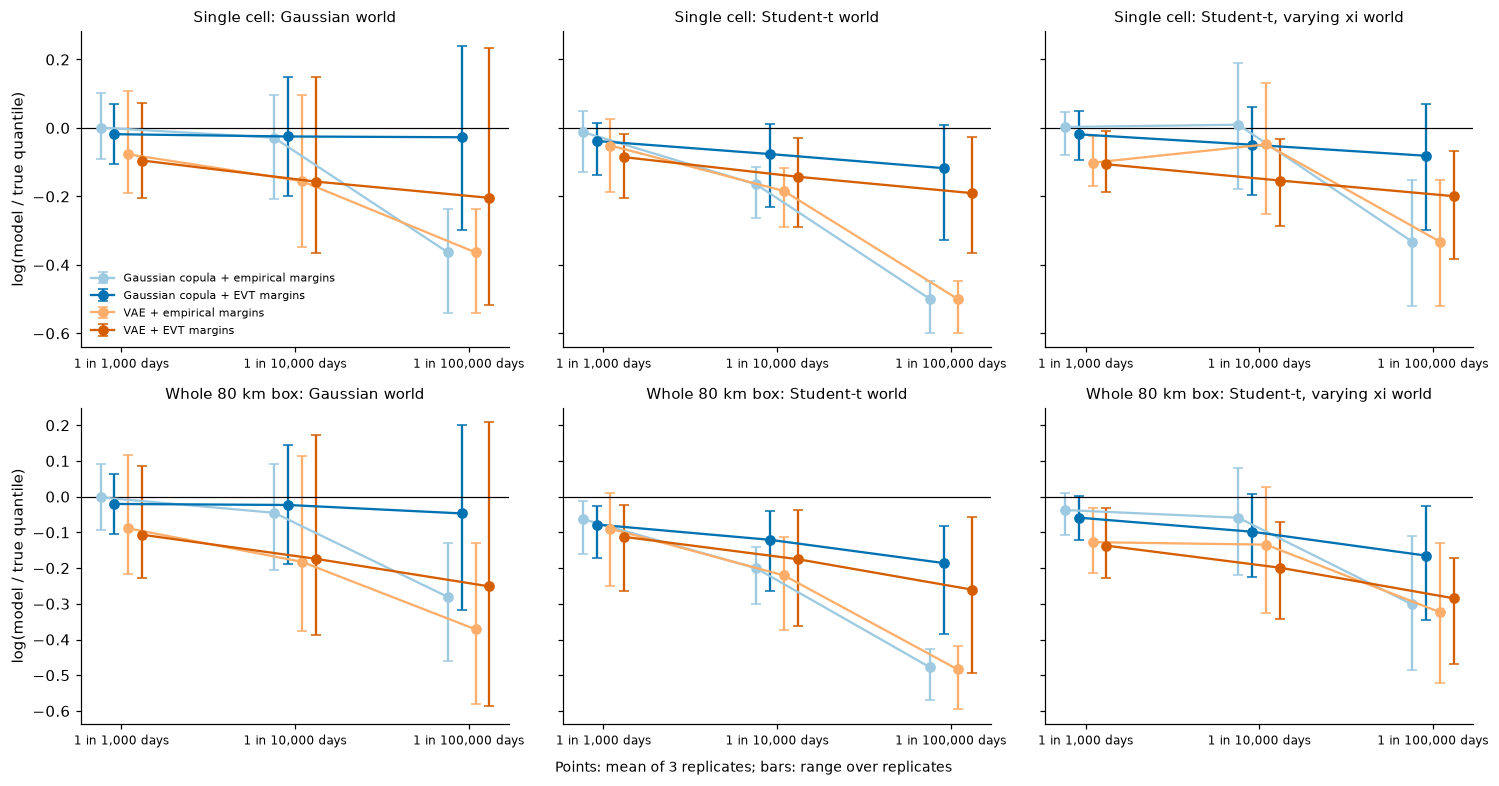

In [5]:
fig, axes = plt.subplots(2, len(WORLDS), figsize=(4.6 * len(WORLDS), 7), sharey="row", squeeze=False)
xs = np.arange(len(PS))
for i, (tile, tname) in enumerate([("1", "Single cell"), ("16", "Whole 80 km box")]):
    for j, w in enumerate(WORLDS):
        ax = axes[i, j]
        for k, name in enumerate(NAMES):
            v = np.array([[r["models"][name]["log_ratio"][tile][str(p)] for p in PS] for r in res["worlds"][w]["reps"]])
            off = (k - 1.5) * 0.08
            ax.errorbar(xs + off, v.mean(0), yerr=[v.mean(0) - v.min(0), v.max(0) - v.mean(0)], fmt="o-",
                        color=COL[name], label=name, capsize=3, lw=1.5)
        ax.axhline(0, color="black", lw=0.8)
        ax.set_xticks(xs); ax.set_xticklabels([LBL[str(p)] + " days" for p in PS], fontsize=8)
        ax.set_title(f"{tname}: {WNAME[w]} world", fontsize=10)
        if j == 0: ax.set_ylabel("log(model / true quantile)")
axes[0, 0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.text(0.5, -0.01, "Points: mean of 3 replicates; bars: range over replicates", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIGS / "simulation_tail_bias.png", bbox_inches="tight"); plt.show()

## Joint extremes: chi(u) against distance

chi(u) is the probability that a cell is extreme (above its u-quantile), given that another cell
at that distance is extreme. It is the most direct measure of whether a generator gets the
**spatial extent** of extremes right. Cell pairs are grouped into contiguous distance bands,
labelled by the band centre.

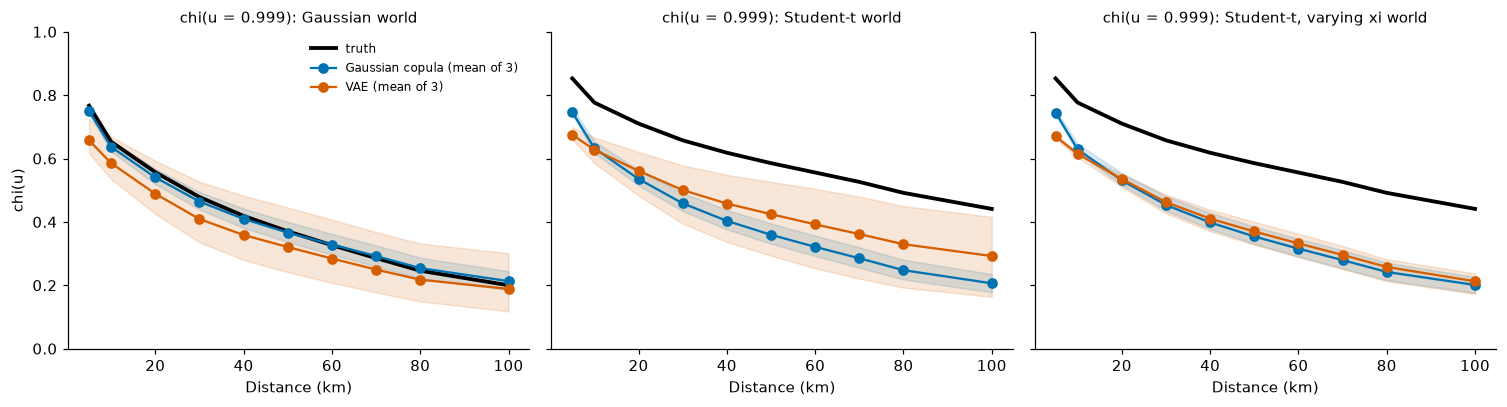

Gaussian               chi(0.999) at 100 km: truth 0.200; Gaussian copula 0.210, 0.244, 0.185; VAE 0.301, 0.118, 0.147
Student-t              chi(0.999) at 100 km: truth 0.441; Gaussian copula 0.206, 0.235, 0.178; VAE 0.416, 0.298, 0.163
Student-t, varying xi  chi(0.999) at 100 km: truth 0.441; Gaussian copula 0.201, 0.226, 0.176; VAE 0.228, 0.172, 0.237


In [6]:
from rainpilot.diagnostics import DIST_BINS as bins
us = res["settings"]["us"]
fig, axes = plt.subplots(1, len(WORLDS), figsize=(4.6 * len(WORLDS), 3.8), sharey=True, squeeze=False)
u = str(us[-1])
for ax, w in zip(axes[0], WORLDS):
    ax.plot(bins, res["worlds"][w]["chi_true"][u], "k-", lw=2.5, label="truth")
    for name in NAMES:
        if "empirical" in name:
            continue   # dependence is shared with the EVT version; chi depends only on ranks
        v = np.array([r["models"][name]["chi"][u] for r in res["worlds"][w]["reps"]])
        ax.plot(bins, v.mean(0), "o-", color=COL[name], label=name.split(" + ")[0] + " (mean of 3)")
        ax.fill_between(bins, v.min(0), v.max(0), color=COL[name], alpha=0.15)
    ax.set_title(f"chi(u = {u}): {WNAME[w]} world", fontsize=10)
    ax.set_xlabel("Distance (km)"); ax.set_ylim(0, 1)
axes[0, 0].set_ylabel("chi(u)"); axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "simulation_chi.png", bbox_inches="tight"); plt.show()
for w in WORLDS:
    i100 = list(bins).index(100)
    print(f"{WNAME[w]:22s} chi({u}) at 100 km: truth {res['worlds'][w]['chi_true'][u][i100]:.3f}; " + "; ".join(
        f"{n.split(' + ')[0]} " + ", ".join(f"{r['models'][n]['chi'][u][i100]:.3f}" for r in res['worlds'][w]['reps'])
        for n in ["Gaussian copula + EVT margins", "VAE + EVT margins"]))

## Reading the results

The interpretation below is written from the run stored in `results/`. If you rerun the study,
check that it still holds. "Bias" is the mean log ratio over cells (or over the box). Ranges are
over the 3 replicates.

**1. Empirical margins fail predictably beyond the training data.** At one day in 100,000, their
single-cell quantiles are too low by about 30% in the Gaussian world (log ratio −0.36), 40% in the
Student-t world (−0.50) and 28% in the varying-ξ world (−0.33), whatever the dependence model. The training set
holds about 7,000 days, so these levels are out of reach.

**2. When the EVT margins are correctly specified, they remove most of that bias on average, but
the tail shape is poorly determined.** With the Gaussian copula, the single-cell bias at one day in
100,000 averages −0.03 (Gaussian world) and −0.12 (Student-t world). The spread between replicates
is wide: in the Gaussian world, −0.30 to +0.24. In all six of these replicates the bias is ordered
by the fitted shared ξ, which ranged from −0.0075 to 0.138 against a true value of 0.0775. About
7,000 strongly dependent days do not pin ξ down, even when it is pooled over 256 cells. These two
worlds are best cases: the truth has exactly the form the EVT margins assume.

**3. When the shared-ξ assumption is wrong, errors appear at the level of single cells.** In the
varying-ξ world (true ξ from −0.02 in the west to 0.18 in the east):
* **Average bias is modest:** −0.08 at one day in 100,000.
* **Single cells are badly off,** with a mean absolute log ratio of 0.22 over the 3 replicates.
  One shared ξ is too heavy in the west and too light in the east, and these cell errors cancel
  in the average.
* **Even an accurate fitted ξ leaves this error.** In the two replicates whose fitted ξ was 0.0825,
  close to the true mean of 0.0775, the mean absolute error was still 0.17–0.18. In the third,
  whose ξ was badly estimated (−0.0075), it was 0.30. In the Student-t world,
  replicates with a well-estimated ξ (0.052 and 0.072) gave only 0.03–0.04.

Averaged over the 3 replicates, EVT margins still beat empirical margins here (mean absolute
error 0.22 against 0.33), but a shared ξ is a real limitation for regional maps of tail risk.

**4. Joint extremes matter for area totals.** In both Student-t worlds the Gaussian copula
underestimates chi at u = 0.999 (0.18–0.24 against a true 0.44 at 100 km). Its bias for the 80 km
box is larger than for single cells (Student-t world: −0.19 against −0.12 at one day in 100,000).
This is consistent with its missing joint dependence. The study does not separate that from the
other causes.

**5. The VAE is inconsistent.**
* **Between replicates:** its chi at u = 0.999 and 100 km varies widely:
  * Student-t: 0.16–0.42 (truth 0.44).
  * Gaussian: 0.12–0.30 (truth 0.20, where the Gaussian copula gets 0.19–0.24).
  * Varying ξ: 0.17–0.24 (truth 0.44).
* **Its tail quantiles are too low on average** even at one day in 1,000 (though not in every
  replicate: Gaussian-world replicate 0 is too high):
  * single cells: −0.10, −0.09 and −0.11 in the three worlds;
  * the box: −0.11 to −0.14.
* **EVT margins help it only partly:** −0.20 against −0.36 (Gaussian world) and −0.19 against −0.50
  (Student-t world) at one day in 100,000.

On real data (notebook 03) the VAE produces too few extreme normal scores, which is consistent
with this, but the simulation does not test that explanation directly.

**Caveats.**
* Only three replicates per world, so the ranges are rough.
* Synthetic days are independent.
* The truth for the 80 km box at one day in 100,000 is itself estimated from 4 million simulated
  days (about 40 exceedances), which adds an error of roughly 0.01–0.02 on the log scale, shared by
  all generators.